# Brain Tumor MRI Classification with Neural Networks and Deep Learning

**Course:** MLAI 504 – Neural Networks and Deep Learning (2026–2027)  
**Author:** Karam Jammal & Yorgo Bou Fayad
**Dataset:** [Brain Tumor MRI Dataset](https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset) (Kaggle, CC0: Public Domain)

## Project goal

Build a neural network that classifies a brain MRI slice into one of four classes: **glioma**, **meningioma**, **pituitary tumor** or **no tumor**. The project follows a systematic approach: data exploration and cleaning, step-by-step model creation, hyperparameter tuning and transfer learning, with every decision explained.

> ⚠️ **Disclaimer:** this is an academic project. The model is not a medical device and must not be used for diagnosis.

## Table of contents

0. Environment setup
1. Dataset selection and description
2. Data exploration and preprocessing
3. Step-by-step model creation
4. Hyperparameter tuning
5. Transfer learning
6. Integration of course topics
7. Evaluation and interpretation
8. Final results and conclusions
9. References

---
# 0. Environment setup

The notebook uses **PyTorch** and **torchvision**. This section installs the two libraries that are not always preinstalled, imports everything, fixes the random seeds and records the library versions so the results can be reproduced. Models are trained on a GPU when one is available: an NVIDIA GPU (CUDA), or the GPU of an Apple-silicon Mac (MPS). The results in this notebook come from a MacBook with an M4 chip, where the whole notebook takes about 3 hours.

In [38]:
# Install the libraries that are not always preinstalled (does nothing if they are already installed)
%pip install -q imagehash kagglehub

Note: you may need to restart the kernel to use updated packages.


In [39]:
import os
import random
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import cv2
import imagehash
import kagglehub
import torch
import torchvision

# Reproducibility: fix the Python, NumPy and PyTorch random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Record the environment
versions = {
    "Python": platform.python_version(),
    "PyTorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "scikit-learn": sklearn.__version__,
    "OpenCV": cv2.__version__,
    "ImageHash": imagehash.__version__,
    "kagglehub": kagglehub.__version__,
}
for name, version in versions.items():
    print(f"{name:<14}: {version}")

# Train on a GPU when one is available: NVIDIA (cuda, e.g. Colab), Apple silicon (mps), otherwise the CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"\nDevice: {device}")

Python        : 3.13.3
PyTorch       : 2.15.0
torchvision   : 0.29.2
NumPy         : 2.5.5
Pandas        : 3.1.1
scikit-learn  : 1.9.1
OpenCV        : 5.1.0
ImageHash     : 4.3.2
kagglehub     : 1.0.3

Device: mps


**Download the dataset.** `kagglehub` downloads the dataset from Kaggle the first time and reuses the local copy afterwards. The folder tree below confirms the data is in place and gives a first image count per class.

In [40]:
# Download the dataset (only the first time; later runs reuse the local copy)
DATA_DIR = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset/versions/2")
print("Dataset location:", DATA_DIR, "\n")

# Print the folder tree with the number of images in each folder
IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")
for root, dirs, files in sorted(os.walk(DATA_DIR)):
    depth = root[len(DATA_DIR):].count(os.sep)
    n_images = sum(f.lower().endswith(IMAGE_EXTENSIONS) for f in files)
    label = f"  ({n_images} images)" if n_images else ""
    print(f"{'    ' * depth}{os.path.basename(root)}/{label}")

Dataset location: /Users/yorgo/.cache/kagglehub/datasets/masoudnickparvar/brain-tumor-mri-dataset/versions/2 

2/
    Testing/
        glioma/  (400 images)
        meningioma/  (400 images)
        notumor/  (400 images)
        pituitary/  (400 images)
    Training/
        glioma/  (1400 images)
        meningioma/  (1400 images)
        notumor/  (1400 images)
        pituitary/  (1400 images)


---
# 1. Dataset selection and description

## Source
We use the **Brain Tumor MRI Dataset** published on Kaggle by Masoud Nickparvar (version 2, CC0: Public Domain). It combines three public datasets: **Figshare**, **SARTAJ** and **Br35H**. The "no tumor" images come from Br35H, and the author replaced SARTAJ's glioma images, which were found to be mislabeled, with images from Figshare.

## Why this dataset
Brain tumors are diagnosed mainly from MRI scans, and the tumor type matters because each type is treated differently. Reading scans takes expert time, so a model that classifies them automatically could support radiologists, for example by flagging the scans that need attention first. The dataset also fits this project well:
- it is an image dataset, which suits CNNs and transfer learning with pretrained models such as ResNet50;
- it is a manageable size (7,200 images, about 150 MB), so models train in minutes on a GPU;
- it has real data-quality problems to solve (different image sizes, black borders, and duplicate images across the training and test sets), which are handled in Section 2.

## Size, features and target
- **Size:** 7,200 JPEG images, provided in a `Training` folder (5,600) and a `Testing` folder (1,600).
- **Features:** the pixel values of each MRI slice. The scans are grayscale and come in different resolutions, so they are resized to a common size during preprocessing.
- **Target variable:** the tumor class, given by the folder name, with four categories:

| Class | Description |
|---|---|
| **glioma** | Tumor that grows from the glial (supporting) cells of the brain; can be slow-growing or aggressive |
| **meningioma** | Tumor of the meninges, the membranes around the brain; usually benign |
| **pituitary** | Tumor of the pituitary gland at the base of the brain; usually benign, but can affect hormones and vision |
| **notumor** | Healthy brain scan with no tumor |

**Image index.** We build a table with one row per image (file path, class and the folder it came from). It is used for counting here and for all preprocessing in Section 2.

In [41]:
from pathlib import Path

CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]

# One row per image: file path, class label and the folder it came from
records = []
for split in ["Training", "Testing"]:
    for label in CLASSES:
        for path in sorted((Path(DATA_DIR) / split / label).iterdir()):
            if path.suffix.lower() in IMAGE_EXTENSIONS:
                records.append({"path": str(path), "label": label, "original_split": split})

df = pd.DataFrame(records)
print(f"Total images: {len(df)}")

# Number of images per class in each folder
counts = pd.crosstab(df["label"], df["original_split"], margins=True, margins_name="Total")
counts[["Training", "Testing", "Total"]]

Total images: 7200


original_split,Training,Testing,Total
label,,,
glioma,1400,400,1800
meningioma,1400,400,1800
notumor,1400,400,1800
pituitary,1400,400,1800
Total,5600,1600,7200


**Sample images.** Four random images per class, with each image's size in pixels (width × height).

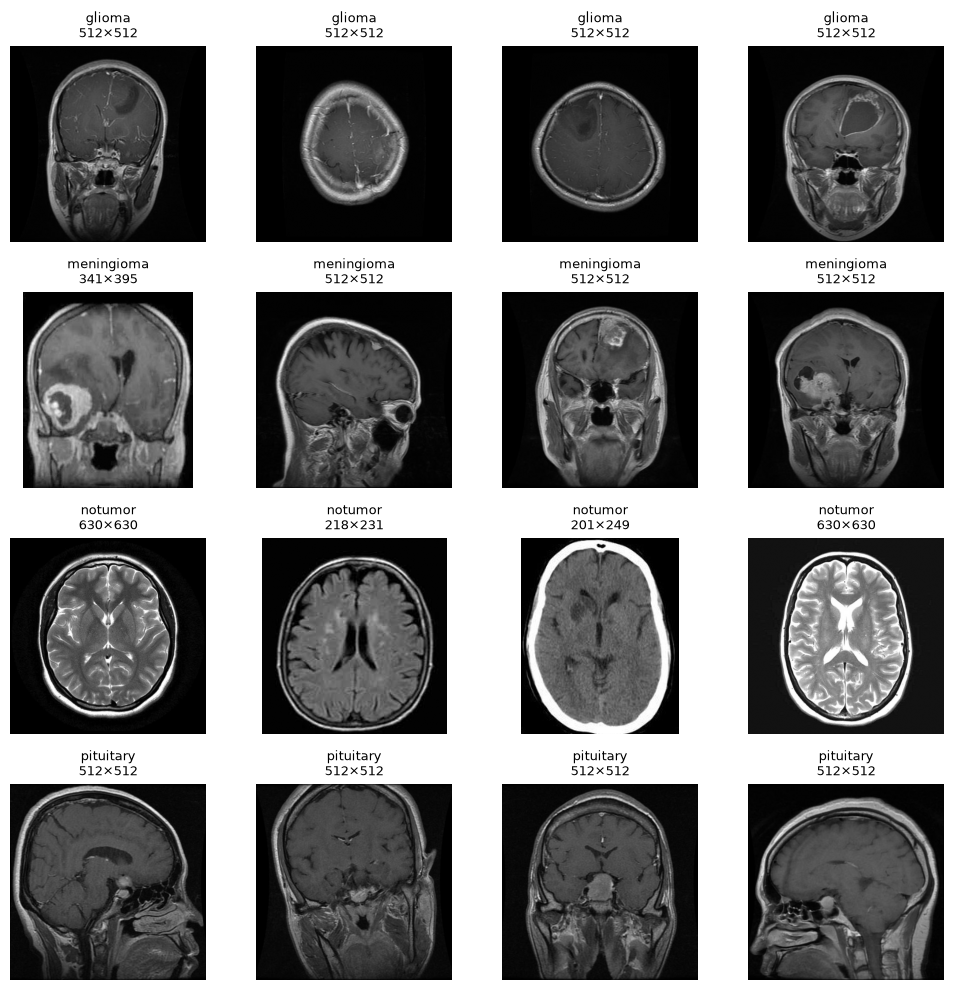

In [42]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(10, 10))

for row, label in enumerate(CLASSES):
    samples = df[df["label"] == label].sample(4, random_state=SEED)
    for col, path in enumerate(samples["path"]):
        img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
        ax = axes[row, col]
        ax.imshow(img, cmap="gray")
        ax.set_title(f"{label}\n{img.shape[1]}×{img.shape[0]}", fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

**Observations**
- The four classes are perfectly balanced in the original dataset (1,800 images each). This changes after duplicate removal (Section 2.2).
- Image sizes vary between images, so all images must be resized to one common size before training.
- Many scans have black borders around the head, which carry no information and can be cropped.
- The scans show different views of the head (from above, from the front and from the side) and different contrast levels, because the images come from three different sources.
- The "notumor" images come from a different source (Br35H) and look different from the tumor images (other sizes and contrast styles). A model could learn these differences instead of the tumor itself, so we keep this in mind when interpreting the results.

---
# 2. Data exploration and preprocessing

Goal: a clean, leakage-free dataset ready for training, in five steps:
1. Integrity check and image sizes
2. Duplicate removal
3. Train / validation / test split
4. Cropping and resizing
5. Pixel scaling and data augmentation

## 2.1 Integrity check, image sizes and outliers
We open every image and record its size, colour mode and average brightness. Images that can't be opened are the image equivalent of missing values and would be removed. Unusually small, large, dark or bright images are the image equivalent of outliers. We also compute a **perceptual hash** for each image: a short fingerprint that stays the same when an image is resized or re-saved, used in 2.2 to find duplicates.

In [43]:
from PIL import Image

def inspect_image(path):
    """Return the image's size, colour mode, average brightness and perceptual hash (or readable=False if it can't be opened)."""
    try:
        with Image.open(path) as img:
            img.load()
            return {"readable": True, "width": img.width, "height": img.height, "mode": img.mode,
                    "brightness": np.asarray(img.convert("L")).mean(), "phash": str(imagehash.phash(img))}
    except Exception:
        return {"readable": False, "width": None, "height": None, "mode": None, "brightness": None, "phash": None}

info = pd.DataFrame([inspect_image(p) for p in df["path"]])
df = pd.concat([df[["path", "label", "original_split"]], info], axis=1)

print("Unreadable images:", (~df["readable"]).sum())
print("Missing labels:", df["label"].isna().sum())
print("Colour modes:", df["mode"].value_counts().to_dict())

# Keep only images that could be opened
df = df[df["readable"]].reset_index(drop=True)

Unreadable images: 0
Missing labels: 0
Colour modes: {'RGB': 4129, 'L': 3067, 'RGBA': 3, 'P': 1}


In [44]:
df["size"] = df["width"].astype(str) + "×" + df["height"].astype(str)
print("Different image sizes:", df["size"].nunique())
print("\nMost common sizes:")
print(df["size"].value_counts().head(5).to_string())
print("\nWidth, height and average brightness (0–255) per class:")
df.groupby("label")[["width", "height", "brightness"]].agg(["min", "median", "max"]).round(1)

Different image sizes: 447

Most common sizes:
size
512×512    5014
225×225     338
630×630      90
201×251      57
228×221      51

Width, height and average brightness (0–255) per class:


width              height              brightness              
             min median   max    min median   max        min median    max
label                                                                     
glioma       175  512.0   640    167  512.0   665       14.9   32.6  122.3
meningioma   174  512.0  1275    195  512.0  1427       18.2   41.3  137.8
notumor      150  228.0  1375    168  243.0  1446       17.4   57.1  126.7
pituitary    201  512.0  1365    202  512.0  1365       24.7   49.6  102.3

**Observations**
- No unreadable images and no missing labels were found.
- The images are stored in several colour modes (4,129 RGB, 3,067 grayscale, 3 RGBA and 1 palette image), even though all scans are grayscale, so every image is loaded as grayscale (1 channel).
- **Size outliers:** there are 447 different image sizes, from 150 to 1,375 pixels wide. Small and large images are kept, because every image is resized to the same size in 2.4.
- **Brightness outliers:** average brightness ranges from about 15 (very dark scans) to about 138 (bright scans). The darkest images are still valid scans with a visible head, so no image is removed. The models see every image scaled to 0–1, and batch normalization (Section 3.3) handles the remaining differences in scale.
- The "notumor" images are mostly smaller (median 228 × 243 vs 512 × 512 pixels) and brighter than the tumor images, which confirms they come from a different source. A model could use these differences as a shortcut instead of the tumor itself.

## 2.2 Duplicates and data leakage
Images with the same hash are copies of each other. A test image with a copy in the training folder is "leaked": the model would be tested on an image it already saw during training, which inflates the test score. We keep one copy of each image, and remove copies that carry different labels, since we can't know which label is correct.

In [45]:
n_with_copy = df.duplicated("phash", keep=False).sum()
print(f"Images that have at least one copy: {n_with_copy}")

# Leakage: test images whose copy is in the training folder
train_hashes = set(df.loc[df["original_split"] == "Training", "phash"])
leaked = df[(df["original_split"] == "Testing") & df["phash"].isin(train_hashes)]
n_test = (df["original_split"] == "Testing").sum()
print(f"Test images with a copy in Training: {len(leaked)} of {n_test} ({len(leaked) / n_test:.1%})")

# Copies with different labels can't be trusted, so they are removed entirely
labels_per_hash = df.groupby("phash")["label"].nunique()
conflicting = labels_per_hash[labels_per_hash > 1].index
print(f"Copies with conflicting labels: {len(conflicting)} groups")

# Keep one copy of every remaining image
clean = df[~df["phash"].isin(conflicting)].drop_duplicates("phash").reset_index(drop=True)
print(f"\nImages: {len(df)} → {len(clean)} after removing duplicates")
print(clean["label"].value_counts().to_string())

Images that have at least one copy: 1580
Test images with a copy in Training: 370 of 1600 (23.1%)
Copies with conflicting labels: 1 groups

Images: 7200 → 6211 after removing duplicates
label
glioma        1774
pituitary     1748
meningioma    1666
notumor       1023


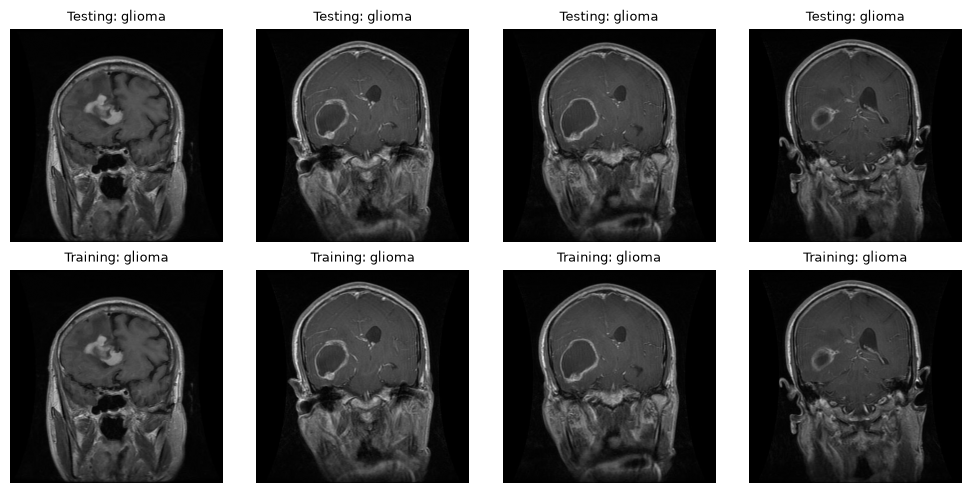

In [46]:
# Leaked test images (top) next to their copy in the training folder (bottom)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for col, (_, test_img) in enumerate(leaked.head(4).iterrows()):
    train_img = df[(df["phash"] == test_img["phash"]) & (df["original_split"] == "Training")].iloc[0]
    for row, img in enumerate([test_img, train_img]):
        axes[row, col].imshow(cv2.imread(img["path"], cv2.IMREAD_GRAYSCALE), cmap="gray")
        axes[row, col].set_title(f"{img['original_split']}: {img['label']}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

**Observations**
- 370 of the 1,600 original test images (23.1%) have an identical copy in the training folder. Testing on the original split would overestimate the model's accuracy, which explains the very high scores often reported for this dataset.
- In total, 1,580 images had at least one copy, and 1 group of copies had conflicting labels and was removed.
- After removing duplicates, 6,211 of 7,200 images remain. The "notumor" class lost the most images (1,800 → 1,023), so the classes are now moderately imbalanced (1,023 to 1,774 per class). We compensate with class weights during training (Section 3).

**Near-duplicates and slices of the same patient.** Exact hash matches miss copies whose contrast was slightly changed, and neighbouring slices of the same patient's scan, which look almost the same. If one of them is in the training set and the other in the test set, the test score is still inflated. We measure how many bits two hashes differ by (the Hamming distance, out of 64) and put images that differ by **4 bits or less** into the same **group**. Groups are kept together in the split (2.3), so similar images never end up in different sets.

In [47]:
from scipy.sparse.csgraph import connected_components

# Each hash is 64 bits, written as 16 hexadecimal characters: turn it into a number
hashes = np.array([int(h, 16) for h in clean["phash"]], dtype=np.uint64)

# Hamming distance between every pair of images: XOR marks the bits that differ, bitwise_count counts them
distance = np.bitwise_count(hashes[:, None] ^ hashes[None, :])

# Images within 4 bits of each other are linked. Images linked directly, or through other images, form one group
NEAR_DUPLICATE_BITS = 4
n_groups, group = connected_components(distance <= NEAR_DUPLICATE_BITS)
clean["group"] = group

group_sizes = clean["group"].value_counts()
print("Images:", len(clean), "in", n_groups, "groups")
print("Images that have at least one near-duplicate:", group_sizes[group_sizes > 1].sum())
print("Largest group:", group_sizes.max(), "images")

Images: 6211 in 4755 groups
Images that have at least one near-duplicate: 2291
Largest group: 14 images


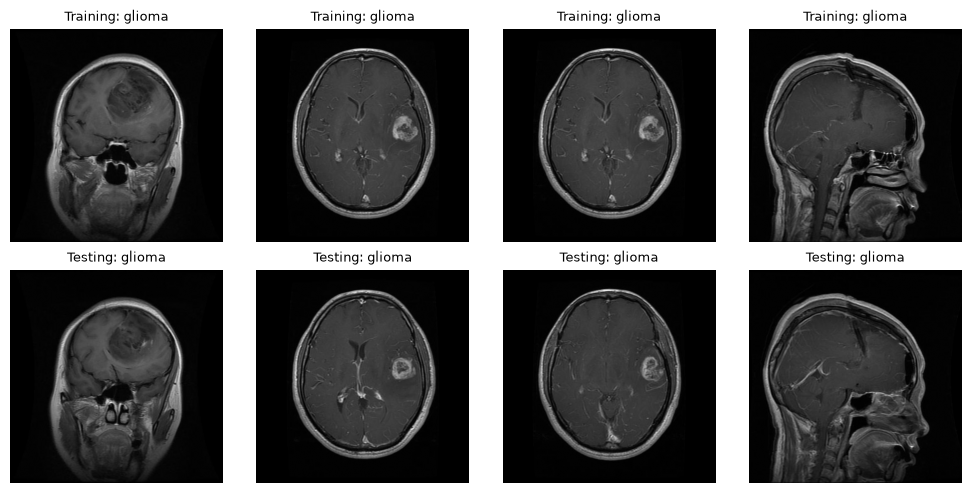

In [48]:
# Four near-duplicate pairs (2 bits apart) where one image is in the Training folder and the other in the Testing folder
rows, cols = np.nonzero(distance == 2)
pairs = []
for a, b in zip(rows, cols):
    if clean.loc[a, "original_split"] == "Training" and clean.loc[b, "original_split"] == "Testing":
        pairs.append((a, b))

fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for col, (a, b) in enumerate(pairs[:4]):
    for row, k in enumerate([a, b]):
        axes[row, col].imshow(cv2.imread(clean.loc[k, "path"], cv2.IMREAD_GRAYSCALE), cmap="gray")
        axes[row, col].set_title(f"{clean.loc[k, 'original_split']}: {clean.loc[k, 'label']}", fontsize=9)
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

**Observations**
- Even after exact duplicates are removed, 2,291 of the 6,211 images (37%) have at least one near-duplicate. They form 4,755 groups, and the largest has 14 images.
- The pairs above come from different original folders and show the same tumor on neighbouring slices, so they are almost certainly slices of the same patient. With a plain random split, the model would be tested on patients it has already seen.
- We use 4 bits as the limit: with 6 bits or more, the links chain unrelated images into very large groups (over 100 images), while 4 bits keeps the groups small.
- The dataset has no patient IDs, so hashing can't find every slice of the same patient. Some of this leakage may remain, and the test score may still be slightly optimistic.

## 2.3 Train / validation / test split
We ignore the original Training/Testing folders and split the clean images about **70% / 15% / 15%**. The split is **stratified**, so each set keeps the same class proportions, and **grouped**, so all images of a near-duplicate group (2.2) go to the same set. `StratifiedGroupKFold` cuts the data into 20 parts of about 5% that respect both rules: 3 parts form the test set, 3 the validation set and the other 14 the training set.
- **Train:** used to fit the models
- **Validation:** used to compare models and choose hyperparameters
- **Test:** used only once, at the very end (Section 7), for the final unbiased score

The split is saved to `data/split_manifest.csv` so it can be reproduced exactly.

In [49]:
from sklearn.model_selection import StratifiedGroupKFold

# Cut the data into 20 parts of about 5%. Each part keeps the class proportions, and a group is never cut in two
folds = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SEED)
clean["part"] = 0
for k, (_, part_rows) in enumerate(folds.split(clean, clean["label"], groups=clean["group"])):
    clean.loc[part_rows, "part"] = k

# 3 parts (15%) for testing, 3 parts (15%) for validation, the other 14 parts (70%) for training
clean["split"] = "train"
clean.loc[clean["part"] < 3, "split"] = "test"
clean.loc[clean["part"].between(3, 5), "split"] = "val"
print(pd.crosstab(clean["label"], clean["split"], margins=True, margins_name="Total")[["train", "val", "test", "Total"]])

# Check: how close is the most similar pair of a training image and a validation or test image?
is_train = (clean["split"] == "train").to_numpy()
print("\nClosest training / non-training pair:", distance[is_train][:, ~is_train].min(), "bits apart")

# Save the split (file paths relative to the dataset folder, so it works on any computer)
clean["file"] = [Path(p).relative_to(DATA_DIR).as_posix() for p in clean["path"]]
os.makedirs("../data", exist_ok=True)
clean[["file", "label", "group", "split"]].to_csv("../data/split_manifest.csv", index=False)

split       train  val  test  Total
label                              
glioma       1242  266   266   1774
meningioma   1165  250   251   1666
notumor       715  154   154   1023
pituitary    1223  263   262   1748
Total        4345  933   933   6211

Closest training / non-training pair: 6 bits apart


## 2.4 Cropping and resizing
Each image is cropped to the box around the head, removing the black borders that carry no information, then resized to **224 × 224** pixels, the input size used by most pretrained models (Section 5). Images stay grayscale (1 channel) and are stored channels-first, with shape (1, 224, 224), which is the layout PyTorch expects.

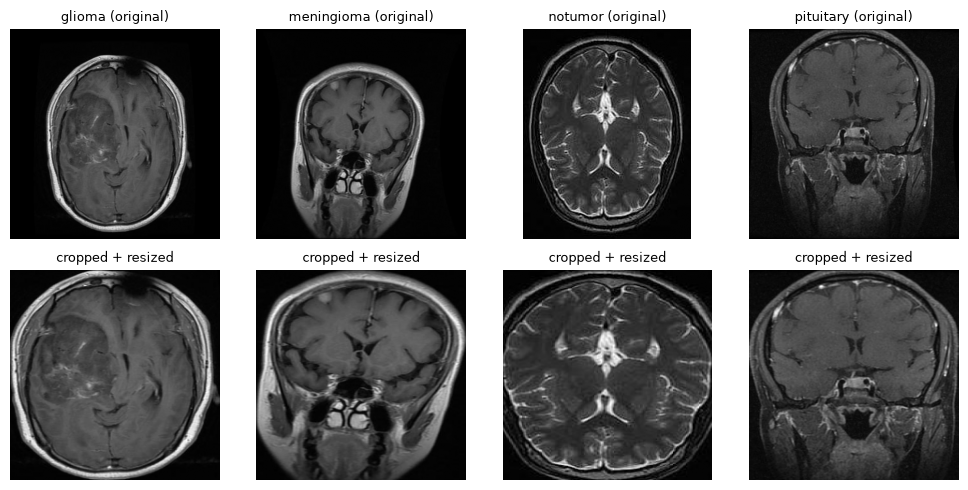

In [50]:
IMG_SIZE = 224

def crop_and_resize(path, size=IMG_SIZE):
    """Crop the image to the head (removing the black borders) and resize it to size × size."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    # Mark the pixels brighter than the background, ignoring small specks of noise
    blurred = cv2.GaussianBlur(img, (5, 5), 0)
    _, mask = cv2.threshold(blurred, 45, 255, cv2.THRESH_BINARY)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    # Crop to the box that contains all the bright pixels (the head)
    ys, xs = np.nonzero(mask)
    if len(xs) > 0:
        img = img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]
    return cv2.resize(img, (size, size), interpolation=cv2.INTER_AREA)

# One example per class: original (top) and after cropping + resizing (bottom)
examples = clean.groupby("label").sample(1, random_state=SEED)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for col, (_, item) in enumerate(examples.iterrows()):
    axes[0, col].imshow(cv2.imread(item["path"], cv2.IMREAD_GRAYSCALE), cmap="gray")
    axes[0, col].set_title(f"{item['label']} (original)", fontsize=9)
    axes[1, col].imshow(crop_and_resize(item["path"]), cmap="gray")
    axes[1, col].set_title("cropped + resized", fontsize=9)
    for row in range(2):
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

In [51]:
def load_split(split):
    """Crop and resize all images of one split; return images (n, 1, 224, 224) and integer labels."""
    part = clean[clean["split"] == split]
    X = np.stack([crop_and_resize(p) for p in part["path"]])[:, np.newaxis]
    y = part["label"].map(CLASSES.index).to_numpy()
    return X, y

X_train, y_train = load_split("train")
X_val, y_val = load_split("val")
X_test, y_test = load_split("test")

print("Train:", X_train.shape, "| Validation:", X_val.shape, "| Test:", X_test.shape)
print("Pixel values:", X_train.min(), "to", X_train.max(), "| type:", X_train.dtype)

Train: (4345, 1, 224, 224) | Validation: (933, 1, 224, 224) | Test: (933, 1, 224, 224)
Pixel values: 0 to 255 | type: uint8


## 2.5 Pixel scaling and data augmentation
- **Scaling:** pixel values (0–255) are scaled to 0–1 each time an image is loaded for training or evaluation (Section 2.6).
- **Augmentation:** during training, each image is randomly flipped left–right, rotated by up to ±18° and zoomed by up to 10%, so the model sees slightly different versions every epoch and generalises better. Left–right flips are realistic because tumors occur on both sides of the brain; upside-down flips are not, so they are not used. Augmentation is applied to the training images only.

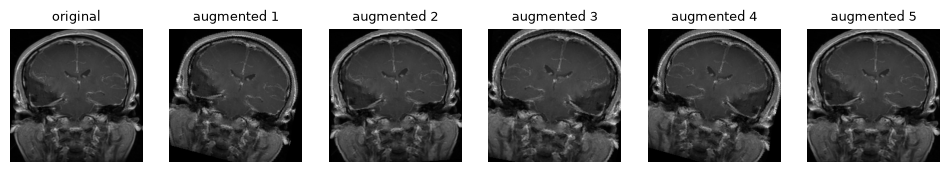

In [52]:
from torchvision.transforms import v2

# Random left–right flip, rotation up to ±18° and zoom up to ±10% (empty areas filled with black)
train_transform = v2.Compose([
    v2.RandomHorizontalFlip(),
    v2.RandomAffine(degrees=18, scale=(0.9, 1.1)),
])

# One training image (scaled to 0–1) and five random augmented versions of it
sample = torch.from_numpy(X_train[0]).float() / 255
plt.figure(figsize=(12, 3))
for i in range(6):
    image = sample if i == 0 else train_transform(sample)
    plt.subplot(1, 6, i + 1)
    plt.imshow(image[0].numpy(), cmap="gray")
    plt.title("original" if i == 0 else f"augmented {i}", fontsize=9)
    plt.axis("off")
plt.show()

## 2.6 Datasets and data loaders
A PyTorch `Dataset` serves one image at a time: it scales the pixels to 0–1 and, for the training set only, applies the augmentation. A `DataLoader` groups the images into batches of 32, shuffled for training.

In [53]:
from torch.utils.data import Dataset, DataLoader

class MRIDataset(Dataset):
    """Serves one image at a time as a float tensor scaled to 0–1, with optional augmentation."""
    def __init__(self, X, y, transform=None):
        self.X = torch.from_numpy(X)                # (n, 1, 224, 224), uint8
        self.y = torch.tensor(y, dtype=torch.long)
        self.transform = transform

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        image = self.X[i].float() / 255             # scale pixels from 0–255 to 0–1
        if self.transform:
            image = self.transform(image)
        return image, self.y[i]

BATCH_SIZE = 32
train_loader = DataLoader(MRIDataset(X_train, y_train, transform=train_transform), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(MRIDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(MRIDataset(X_test, y_test), batch_size=BATCH_SIZE)

images, labels = next(iter(train_loader))
print("One training batch:", tuple(images.shape), images.dtype, "| labels:", tuple(labels.shape))
print(f"Pixel values in the batch: {images.min():.2f} to {images.max():.2f}")

One training batch: (32, 1, 224, 224) torch.float32 | labels: (32,)
Pixel values in the batch: 0.00 to 1.00


**Preprocessing summary**

| Step | Result |
|---|---|
| Integrity check | 0 unreadable images, 0 missing labels |
| Outliers | sizes from 150 to 1,375 pixels wide and dark or bright scans kept: all are valid, and resizing and scaling handle them |
| Exact duplicates | 7,200 → 6,211 images (370 test images had a copy in training) |
| Near-duplicates | 4,755 groups of near-identical images (hashes within 4 bits), each kept in one set |
| Split | 4,345 train / 933 validation / 933 test, stratified and grouped |
| Cropping and resizing | all images 224 × 224, grayscale, shape (1, 224, 224) |
| Scaling | 0–255 → 0–1 when each image is loaded |
| Augmentation | flip, rotation, zoom (training only) |
| Data loaders | batches of 32, shuffled for training |

---
# 3. Step-by-step model creation

We build the model in small steps. Each step changes one thing, and all models are compared on the validation set. Every model is trained the same way:
- **Loss:** cross-entropy, the standard loss for multi-class classification. In PyTorch it includes the softmax, so the models output one raw score per class.
- **Optimizer:** Adam with learning rate 0.001 (tuned in Section 4)
- **Epochs and batch size:** up to 30 epochs, in batches of 32 images
- **Early stopping:** training stops when the validation loss hasn't improved for 5 epochs, and the weights from the best epoch are kept
- **Class weights:** mistakes on smaller classes count more, to compensate for the imbalance left after duplicate removal
- **Monitoring:** after every epoch, one line shows the training and validation loss and accuracy

In [54]:
import time
import torch.nn as nn
from sklearn.utils.class_weight import compute_class_weight

# Class weights: smaller classes get a larger weight in the loss
weights = compute_class_weight("balanced", classes=np.arange(len(CLASSES)), y=y_train)
class_weights = torch.tensor(weights, dtype=torch.float32).to(device)
print("Class weights:", {c: round(float(w), 2) for c, w in zip(CLASSES, weights)})

# Training images without augmentation, for the first three models (augmentation is added in 3.4)
plain_train_loader = DataLoader(MRIDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)

EPOCHS = 30    # maximum number of epochs
PATIENCE = 5   # early stopping: stop after 5 epochs without improvement of the validation loss
results = {}   # validation accuracy of each model, for the comparison table
histories = {} # per-epoch history and best epoch of each model

# The weights of the key models are saved here, so they can be reloaded if the session is lost
MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)

Class weights: {'glioma': 0.87, 'meningioma': 0.93, 'notumor': 1.52, 'pituitary': 0.89}


**Training loop.** Written once and reused for every model. In each epoch, the model makes one pass over the training data (for every batch: forward pass, loss, backpropagation, weight update), then it is evaluated on the validation set. Early stopping keeps the weights from the epoch with the lowest validation loss. The optimizer (Adam or SGD with momentum), the L2 weight decay and the amount of printing can be changed for the tuning in Section 4. Only trainable layers are passed to the optimizer, and frozen batch-normalization layers are kept in evaluation mode, which matters for the frozen layers in Section 5.

**Batch-norm statistics.** During training, a batch-norm layer normalizes each batch with that batch's own mean and variance. For evaluation it uses a stored mean and variance instead. By default PyTorch stores a moving average that mostly reflects the last few batches of the epoch. In our first full run this made the validation accuracy of every batch-norm model jump up and down (for example from 81% to 20% and back within four epochs), even on training images. So after each epoch we recompute the stored statistics over the whole training set with the final weights of the epoch ("precise batch norm", Wu & Johnson, 2021). In a test, this turned the jumping curve (72%, 56%, 53%, 61%, 44%, …) into a smooth one (71%, 78%, 79%, 82%, 82%, …). It costs one extra pass over the training images per epoch, without computing gradients.

In [55]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    """One pass over the training data. Returns the average loss and the accuracy."""
    model.train()
    # Batch-norm layers that are frozen (Section 5) stay in evaluation mode, so their statistics stay fixed too
    for layer in model.modules():
        if isinstance(layer, nn.BatchNorm2d) and not layer.weight.requires_grad:
            layer.eval()
    total_loss, correct = 0.0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()              # reset the gradients from the previous batch
        outputs = model(images)            # forward pass: one score per class
        loss = loss_fn(outputs, labels)
        loss.backward()                    # backpropagation: compute the gradients
        optimizer.step()                   # update the weights
        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)


def update_batchnorm_statistics(model, loader):
    """Recompute the mean and variance stored in each trainable batch-norm layer, over the whole training set."""
    batchnorm_layers = [layer for layer in model.modules()
                        if isinstance(layer, nn.BatchNorm2d) and layer.weight.requires_grad]
    if not batchnorm_layers:      # models without batch norm (or with frozen batch norm) have nothing to update
        return
    model.eval()                  # everything else (dropout, frozen layers) in evaluation mode
    for layer in batchnorm_layers:
        layer.reset_running_stats()
        layer.momentum = None     # None = plain average over all batches instead of a moving average
        layer.train()             # only these layers collect statistics
    with torch.no_grad():         # no gradients and no weight updates, just a forward pass
        for images, _ in loader:
            model(images.to(device))


def evaluate(model, loader, loss_fn):
    """Average loss and accuracy on a dataset, without updating the weights."""
    model.eval()
    total_loss, correct = 0.0, 0
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            total_loss += loss_fn(outputs, labels).item() * len(labels)
            correct += (outputs.argmax(dim=1) == labels).sum().item()
    return total_loss / len(loader.dataset), correct / len(loader.dataset)


def plot_history(history, title):
    """Plot the training and validation loss and accuracy per epoch."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for ax, metric in zip(axes, ["loss", "accuracy"]):
        ax.plot(epochs, history["train_" + metric], label="train")
        ax.plot(epochs, history["val_" + metric], label="validation")
        ax.set_title(f"{title}: {metric}")
        ax.set_xlabel("epoch")
        ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
        ax.legend()
    plt.tight_layout()
    plt.show()


def train_model(model, name, loader=train_loader, learning_rate=0.001, epochs=EPOCHS,
                optimizer="adam", weight_decay=0.0, verbose=True):
    """Train with early stopping, print one line per epoch, then plot the learning curves.
    optimizer is "adam" or "sgd" (SGD with momentum 0.9), weight_decay is the L2 regularization strength,
    and verbose=False hides the epoch lines and the plot (used for the many runs of Section 4)."""
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss(weight=class_weights)
    trainable = [p for p in model.parameters() if p.requires_grad]   # frozen layers (Section 5) are left out
    if optimizer == "adam":
        opt = torch.optim.Adam(trainable, lr=learning_rate, weight_decay=weight_decay)
    else:
        opt = torch.optim.SGD(trainable, lr=learning_rate, momentum=0.9, weight_decay=weight_decay)
    history = {"train_loss": [], "train_accuracy": [], "val_loss": [], "val_accuracy": []}
    best_val_loss, best_weights, best_epoch, epochs_without_improvement = float("inf"), None, 0, 0

    n_parameters = sum(p.numel() for p in model.parameters())
    n_trainable = sum(p.numel() for p in trainable)
    print(f"Training: {name} ({n_parameters:,} parameters, {n_trainable:,} trainable)")
    for epoch in range(1, epochs + 1):
        start = time.time()
        train_loss, train_acc = train_one_epoch(model, loader, loss_fn, opt)
        update_batchnorm_statistics(model, plain_train_loader)   # training images without augmentation
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)
        if verbose:
            print(f"Epoch {epoch:2d} | train: loss {train_loss:.4f}, accuracy {train_acc:.4f} | "
                  f"validation: loss {val_loss:.4f}, accuracy {val_acc:.4f} | {time.time() - start:.0f}s")

        # Early stopping: remember the best weights, stop after PATIENCE epochs without improvement
        if val_loss < best_val_loss:
            best_val_loss, best_epoch, epochs_without_improvement = val_loss, epoch, 0
            best_weights = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement == PATIENCE:
                print(f"Early stopping: no improvement for {PATIENCE} epochs")
                break

    model.load_state_dict(best_weights)
    _, results[name] = evaluate(model, val_loader, loss_fn)
    history["best_epoch"] = best_epoch
    histories[name] = history
    print(f"Best weights restored (epoch {best_epoch}): validation accuracy {results[name]:.4f}")
    if verbose:
        plot_history(history, name)
    return model

## 3.1 Baseline: fully connected network (MLP)
Every pixel is a separate input, so this model ignores which pixels are next to each other. It is our baseline: any useful model must beat it.

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=50176, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=4, bias=True)
)
Training: 1. MLP baseline (6,423,172 parameters, 6,423,172 trainable)
Epoch  1 | train: loss 1.3729, accuracy 0.4817 | validation: loss 0.9105, accuracy 0.6302 | 2s
Epoch  2 | train: loss 0.8665, accuracy 0.6419 | validation: loss 0.9550, accuracy 0.6131 | 1s
Epoch  3 | train: loss 0.7670, accuracy 0.6884 | validation: loss 0.9607, accuracy 0.6270 | 1s
Epoch  4 | train: loss 0.6862, accuracy 0.7326 | validation: loss 0.8056, accuracy 0.6913 | 1s
Epoch  5 | train: loss 0.6009, accuracy 0.7701 | validation: loss 0.7828, accuracy 0.7192 | 1s
Epoch  6 | train: loss 0.5483, accuracy 0.7860 | validation: loss 0.8216, accuracy 0.6892 | 1s
Epoch  7 | train: loss 0.5133, accuracy 0.8016 | validation: loss 0.8655, accuracy 0.6592 | 1s
Epoch  8 | train: loss 0.4593, accuracy 0.8232 | validation: loss 0.7552, acc

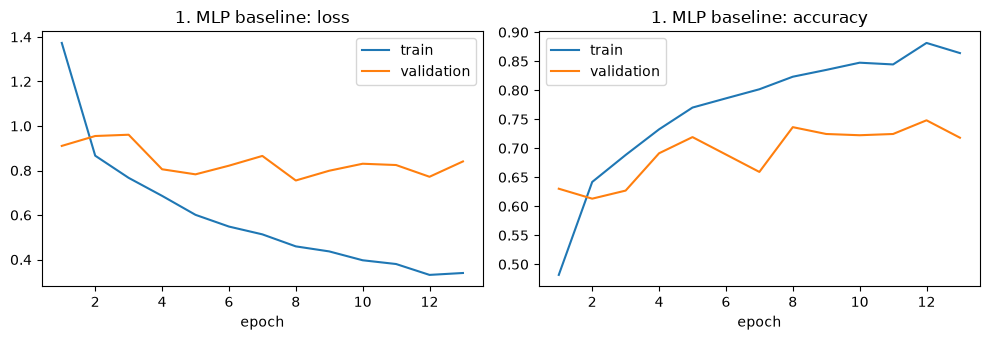

In [56]:
mlp = nn.Sequential(
    nn.Flatten(),                           # (1, 224, 224) image → 50,176 values
    nn.Linear(IMG_SIZE * IMG_SIZE, 128),
    nn.ReLU(),
    nn.Linear(128, len(CLASSES)),           # one score per class
)
print(mlp)
mlp = train_model(mlp, "1. MLP baseline", loader=plain_train_loader)
torch.save(mlp.state_dict(), f"{MODEL_DIR}/mlp.pt")

**Observations**
- The best validation accuracy is **73.6%** (epoch 8). That is well above chance (25%), so even single pixels carry some information.
- After epoch 8 the training accuracy keeps rising (88% at epoch 12), but the validation loss goes up: the model starts to memorize the training images. This is **overfitting**.
- With 6.4 million parameters for 4,345 images, and no idea which pixels are neighbours, the MLP has to learn every pattern separately at every position. This is the weakness that convolutions fix.
- Each epoch takes only about 1 second, because the model is just two matrix multiplications.

## 3.2 Simple CNN
Convolution layers slide small filters over the image to detect local patterns (edges, textures, shapes), and pooling layers shrink the image step by step. Two convolution blocks, followed by the same classifier as the MLP.

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=186624, out_features=128, bias=True)
  (8): ReLU()
  (9): Linear(in_features=128, out_features=4, bias=True)
)
Training: 2. Simple CNN (23,907,332 parameters, 23,907,332 trainable)
Epoch  1 | train: loss 0.8489, accuracy 0.6601 | validation: loss 0.6503, accuracy 0.7846 | 16s
Epoch  2 | train: loss 0.4219, accuracy 0.8433 | validation: loss 0.5254, accuracy 0.8060 | 16s
Epoch  3 | train: loss 0.2522, accuracy 0.9084 | validation: loss 0.4907, accuracy 0.8264 | 16s
Epoch  4 | train: loss 0.1437, accuracy 0.9471 | validation: loss 0.6144, accuracy 0.8028 | 16s
Epoch  5 | train: loss 0.1067, accuracy 0.9627 | val

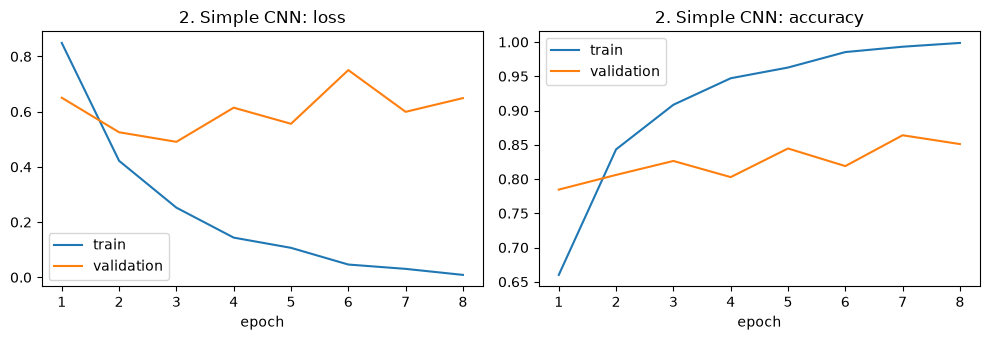

In [57]:
simple_cnn = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3), nn.ReLU(), nn.MaxPool2d(2),    # 224 → 222 → 111 pixels
    nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(), nn.MaxPool2d(2),   # 111 → 109 → 54 pixels
    nn.Flatten(),                                                   # 64 × 54 × 54 = 186,624 values
    nn.Linear(64 * 54 * 54, 128), nn.ReLU(),
    nn.Linear(128, len(CLASSES)),
)
print(simple_cnn)
simple_cnn = train_model(simple_cnn, "2. Simple CNN", loader=plain_train_loader)

**Observations**
- Validation accuracy goes up from 73.6% to **82.6%**, so looking at local patterns instead of single pixels clearly helps.
- The model overfits quickly: training accuracy reaches 99.9% by epoch 8, while the validation loss is lowest at epoch 3 and then goes up. Early stopping keeps the epoch-3 weights (it uses the validation loss, so it does not keep epoch 7, which had a higher accuracy of 86.4% but a higher loss).
- Almost all of the 23.9 million parameters sit in one layer: Flatten turns the 64 × 54 × 54 feature maps into 186,624 numbers, and each one is connected to 128 neurons. That huge layer is what makes memorizing so easy.

## 3.3 Deeper CNN with batch normalization
Four convolution blocks with more filters in each, so the model can learn more complex shapes. **Batch normalization** keeps the values inside the network on a stable scale, which makes training faster and more stable. **Global average pooling** replaces Flatten by averaging each feature map to a single number, which cuts the number of parameters from about 24 million to about 0.4 million. The `build_cnn` function is reused in the next steps and in Section 4.

Sequential(
  (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (2): ReLU()
  (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (6): ReLU()
  (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (10): ReLU()
  (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (12): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (13): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=Tru

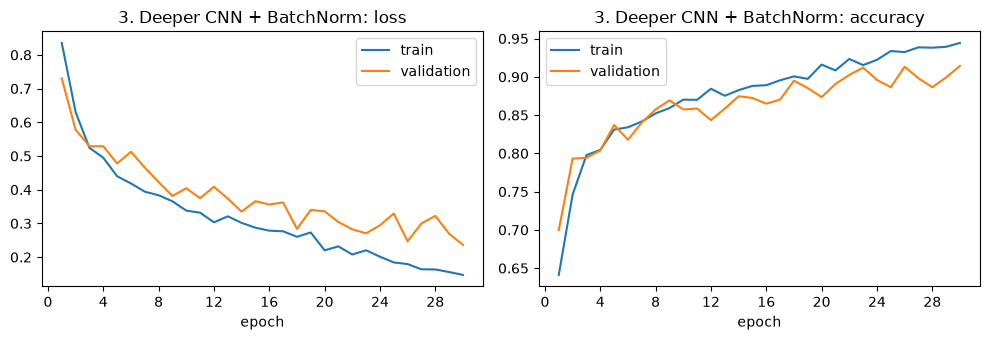

In [58]:
def build_cnn(activation=nn.ReLU, dropout=0.0, filters=(32, 64, 128, 256), dense_units=128):
    """Deeper CNN: one block per filter size (Conv → BatchNorm → activation → MaxPool), then a small classifier."""
    layers, in_channels = [], 1
    for f in filters:
        layers += [nn.Conv2d(in_channels, f, kernel_size=3, padding=1, bias=False),
                   nn.BatchNorm2d(f), activation(), nn.MaxPool2d(2)]
        in_channels = f
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(),     # global average pooling
               nn.Linear(in_channels, dense_units), activation(),
               nn.Dropout(dropout),                       # dropout = 0 means no dropout
               nn.Linear(dense_units, len(CLASSES))]
    return nn.Sequential(*layers)

deeper_cnn = build_cnn()
print(deeper_cnn)
deeper_cnn = train_model(deeper_cnn, "3. Deeper CNN + BatchNorm", loader=plain_train_loader)

**Observations**
- This is the best model of Section 3: **91.4%** validation accuracy, 8.8 points more than the simple CNN, with **57 times fewer parameters** (0.42 million instead of 23.9 million), thanks to global average pooling.
- Overfitting is much smaller: at the last epoch, training accuracy is 94.4% and validation accuracy 91.4%. For the simple CNN, the gap was about 15 points (99.9% vs 85.1%).
- The best epoch is the last one (30), so the model was still improving when it hit the 30-epoch limit.
- In our first run, the validation accuracy of this model jumped between 20% and 81%. The batch-norm fix in the training loop (Section 3) made the curve smooth.

## 3.4 Regularization: data augmentation and dropout
To reduce overfitting, the model is now trained on the augmented training images (Section 2.6), and **dropout** randomly switches off 50% of the classifier's neurons at each training step, so the model can't rely on just a few of them.

Training: 4. + augmentation + dropout (421,732 parameters, 421,732 trainable)
Epoch  1 | train: loss 0.9444, accuracy 0.5855 | validation: loss 0.7703, accuracy 0.6977 | 30s
Epoch  2 | train: loss 0.7421, accuracy 0.7010 | validation: loss 0.6689, accuracy 0.7299 | 30s
Epoch  3 | train: loss 0.6268, accuracy 0.7583 | validation: loss 0.5698, accuracy 0.7792 | 30s
Epoch  4 | train: loss 0.5953, accuracy 0.7712 | validation: loss 0.5293, accuracy 0.7974 | 30s
Epoch  5 | train: loss 0.5505, accuracy 0.7862 | validation: loss 0.5229, accuracy 0.7846 | 30s
Epoch  6 | train: loss 0.4984, accuracy 0.8113 | validation: loss 0.4640, accuracy 0.8285 | 30s
Epoch  7 | train: loss 0.4907, accuracy 0.8122 | validation: loss 0.4720, accuracy 0.8371 | 30s
Epoch  8 | train: loss 0.4734, accuracy 0.8182 | validation: loss 0.4522, accuracy 0.8392 | 30s
Epoch  9 | train: loss 0.4537, accuracy 0.8242 | validation: loss 0.4743, accuracy 0.8124 | 30s
Epoch 10 | train: loss 0.4416, accuracy 0.8329 | validatio

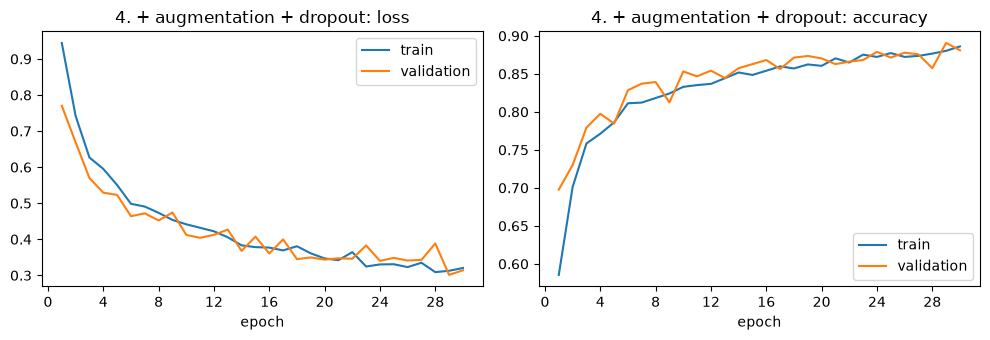

In [59]:
regularized_cnn = build_cnn(dropout=0.5)
regularized_cnn = train_model(regularized_cnn, "4. + augmentation + dropout", loader=train_loader)

**Observations**
- Validation accuracy is **89.1%** (epoch 29), 2.3 points lower than the same network without augmentation and dropout (91.4%).
- Overfitting is gone: training and validation accuracy are almost the same (about 88–89%). The training images are now harder (randomly rotated, zoomed and flipped) and half of the classifier neurons are switched off at each step, so the model can't memorize them.
- The cost is slower learning. The curves are still going up at epoch 30, so with 30 epochs this model is **underfitting** rather than overfitting. With more epochs it would probably catch up.
- We keep augmentation and dropout for the next steps. A model with no gap between training and validation should generalize better to new images, and the tuning in Section 4 can make up for the slower learning.

## 3.5 Activation functions
We compare ReLU (used so far) with two variants designed to avoid "dead" neurons that stop learning: **Leaky ReLU**, which lets a small signal through for negative values, and **ELU**, which is smooth for negative values.

Training: 5. Activation: Leaky ReLU (421,732 parameters, 421,732 trainable)
Epoch  1 | train: loss 0.9581, accuracy 0.5963 | validation: loss 0.7838, accuracy 0.6902 | 30s
Epoch  2 | train: loss 0.7863, accuracy 0.6854 | validation: loss 0.7000, accuracy 0.7278 | 30s
Epoch  3 | train: loss 0.6631, accuracy 0.7415 | validation: loss 0.6071, accuracy 0.7781 | 32s
Epoch  4 | train: loss 0.6037, accuracy 0.7602 | validation: loss 0.6164, accuracy 0.7889 | 30s
Epoch  5 | train: loss 0.5754, accuracy 0.7768 | validation: loss 0.5517, accuracy 0.8092 | 30s
Epoch  6 | train: loss 0.5232, accuracy 0.8007 | validation: loss 0.4852, accuracy 0.8210 | 30s
Epoch  7 | train: loss 0.5043, accuracy 0.8051 | validation: loss 0.4578, accuracy 0.8339 | 30s
Epoch  8 | train: loss 0.4709, accuracy 0.8196 | validation: loss 0.4614, accuracy 0.8210 | 30s
Epoch  9 | train: loss 0.4636, accuracy 0.8186 | validation: loss 0.4313, accuracy 0.8360 | 30s
Epoch 10 | train: loss 0.4372, accuracy 0.8322 | validation:

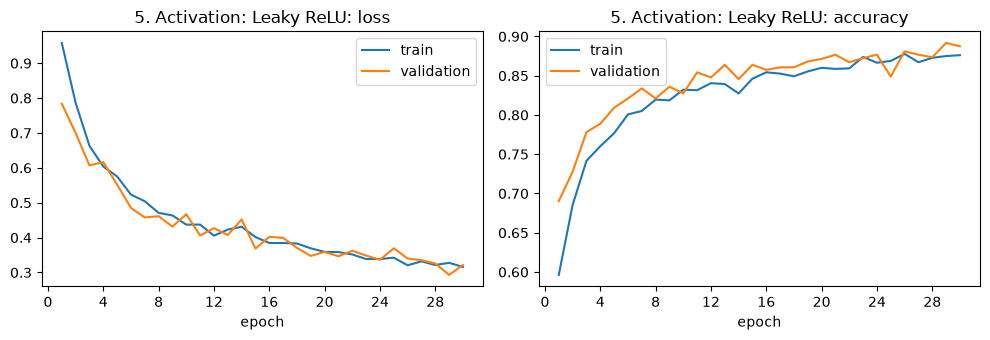

Training: 5. Activation: ELU (421,732 parameters, 421,732 trainable)
Epoch  1 | train: loss 0.9122, accuracy 0.6145 | validation: loss 0.7366, accuracy 0.7053 | 30s
Epoch  2 | train: loss 0.7769, accuracy 0.6879 | validation: loss 0.6830, accuracy 0.7267 | 30s
Epoch  3 | train: loss 0.7029, accuracy 0.7206 | validation: loss 0.6532, accuracy 0.7385 | 30s
Epoch  4 | train: loss 0.6456, accuracy 0.7438 | validation: loss 0.6046, accuracy 0.7653 | 30s
Epoch  5 | train: loss 0.6291, accuracy 0.7494 | validation: loss 0.6181, accuracy 0.7556 | 30s
Epoch  6 | train: loss 0.5796, accuracy 0.7756 | validation: loss 0.5875, accuracy 0.7728 | 30s
Epoch  7 | train: loss 0.5575, accuracy 0.7860 | validation: loss 0.5957, accuracy 0.7631 | 30s
Epoch  8 | train: loss 0.5445, accuracy 0.7938 | validation: loss 0.4958, accuracy 0.8317 | 30s
Epoch  9 | train: loss 0.5350, accuracy 0.7972 | validation: loss 0.5131, accuracy 0.8264 | 30s
Epoch 10 | train: loss 0.5218, accuracy 0.7998 | validation: loss 0

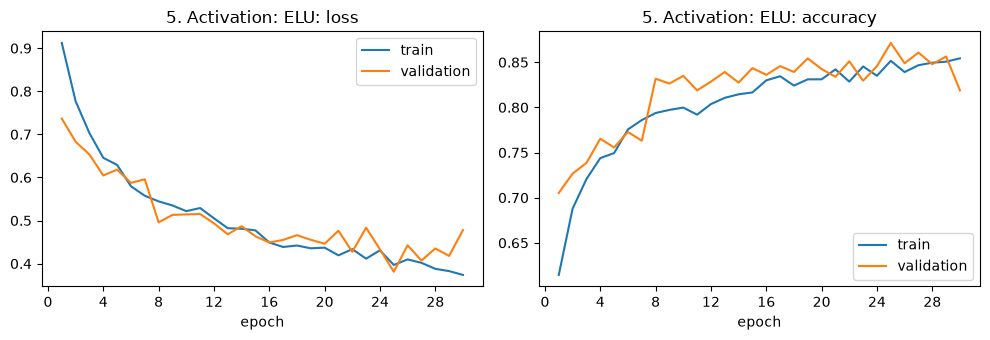

In [60]:
for name, activation in [("Leaky ReLU", nn.LeakyReLU), ("ELU", nn.ELU)]:
    model = build_cnn(activation=activation, dropout=0.5)
    train_model(model, f"5. Activation: {name}", loader=train_loader)

**Observations**
- **Leaky ReLU** reaches 89.2% and ReLU (model 4) reached 89.1%. That difference is 1 image out of 933, so the two are equal.
- **ELU** is a bit lower, at 87.1%, and learned more slowly. It stopped early at epoch 30, with its best epoch at 25.
- Dead neurons don't seem to be a problem here: batch normalization keeps the values before each activation centred around zero, so most ReLU neurons stay active. We keep **ReLU** because it is the simplest and works just as well.

## 3.6 Comparison
Validation accuracy of every model built in this section.

In [61]:
pd.Series(results, name="validation accuracy").round(4).to_frame()

,validation accuracy
1. MLP baseline,0.7363
2. Simple CNN,0.8264
3. Deeper CNN + BatchNorm,0.9143
4. + augmentation + dropout,0.8907
5. Activation: Leaky ReLU,0.8917
5. Activation: ELU,0.8714


**Observations**
- Each step of Section 3 changed one thing, so each difference can be explained:
  - **MLP → simple CNN (+8.9 points):** convolutions use the fact that neighbouring pixels belong together.
  - **Simple CNN → deeper CNN (+8.8 points):** more layers, batch normalization and global average pooling learn better features with far fewer parameters.
  - **Augmentation and dropout (−2.3 points):** they removed the overfitting but slowed learning, and 30 epochs were not enough.
  - **Activations:** they made no real difference.
- Each model was trained once with one random seed, so differences under about 1–2 points (9–19 validation images) should not be over-interpreted.
- The best Section 3 model is the deeper CNN at 91.4%. Section 4 tunes the regularized version (augmentation + dropout), because it has no overfitting gap and the most room to improve with better settings.

---
# 4. Hyperparameter tuning

We tune the regularized deeper CNN from 3.4 (batch normalization, augmentation, dropout, ReLU) in four steps:
1. **Random search** over the learning rate, dropout, network size and L2 weight decay
2. **Batch size:** 16, 32 and 64 with the best configuration
3. **Optimizer:** Adam vs SGD with momentum
4. **Final tuned model**, retrained with the best settings

All choices are made on the **validation** set; the test set is still not used. To save GPU time, search runs stop after at most 15 epochs. The **number of epochs** is not searched: early stopping picks it for every run, and the tables show the best epoch.

## 4.1 Random search
Each run draws one value for every setting below and trains a new model. **Why random search and not grid search?** With the same number of runs, a grid tries only a few values of each setting, while random search tries a new value of every setting in every run, which finds good values of the setting that matters most much faster (Bergstra & Bengio, 2012). The learning rate is drawn on a log scale, so 0.0001–0.001 is searched as thoroughly as 0.001–0.003.

| Setting | Values |
|---|---|
| Learning rate | 0.0001 to about 0.003 (log scale) |
| Dropout | 0.3 or 0.5 |
| Filters | 16 → 128 or 32 → 256 |
| Classifier size | 64, 128 or 256 units |
| L2 weight decay | 0 or 0.0001 |

In [62]:
N_RUNS = 10          # number of random configurations
SEARCH_EPOCHS = 15   # maximum epochs per run (early stopping can stop earlier)

random.seed(SEED)    # the search draws the same 10 configurations every time the notebook runs
search_results = []
for run in range(1, N_RUNS + 1):
    config = {
        "learning_rate": 10 ** random.uniform(-4, -2.5),   # from 0.0001 to about 0.003, on a log scale
        "dropout": random.choice([0.3, 0.5]),
        "filters": random.choice([(16, 32, 64, 128), (32, 64, 128, 256)]),
        "dense_units": random.choice([64, 128, 256]),
        "weight_decay": random.choice([0, 0.0001]),
    }
    torch.manual_seed(SEED)   # same random starting weights in every run, so only the settings differ
    model = build_cnn(dropout=config["dropout"], filters=config["filters"], dense_units=config["dense_units"])
    name = f"search run {run}"
    train_model(model, name, learning_rate=config["learning_rate"], weight_decay=config["weight_decay"],
                epochs=SEARCH_EPOCHS, verbose=False)

    config["best epoch"] = histories[name]["best_epoch"]
    config["validation accuracy"] = results.pop(name)   # pop: the search runs stay out of the main comparison table
    search_results.append(config)

search_table = pd.DataFrame(search_results).sort_values("validation accuracy", ascending=False)
search_table.round({"learning_rate": 5, "validation accuracy": 4})

Training: search run 1 (405,028 parameters, 405,028 trainable)
Best weights restored (epoch 13): validation accuracy 0.8746
Training: search run 2 (131,444 parameters, 131,444 trainable)
Best weights restored (epoch 15): validation accuracy 0.8478
Training: search run 3 (105,908 parameters, 105,908 trainable)
Best weights restored (epoch 15): validation accuracy 0.8392
Training: search run 4 (114,420 parameters, 114,420 trainable)
Best weights restored (epoch 14): validation accuracy 0.8617
Training: search run 5 (131,444 parameters, 131,444 trainable)
Best weights restored (epoch 15): validation accuracy 0.8617
Training: search run 6 (114,420 parameters, 114,420 trainable)
Best weights restored (epoch 14): validation accuracy 0.8532
Training: search run 7 (421,732 parameters, 421,732 trainable)
Best weights restored (epoch 14): validation accuracy 0.8553
Training: search run 8 (114,420 parameters, 114,420 trainable)
Best weights restored (epoch 11): validation accuracy 0.8499
Training

,learning_rate,dropout,filters,dense_units,weight_decay,best epoch,validation accuracy
0,0.00091,0.3,"(32, 64, 128, 256)",64,0.0000,13,0.8746
3,0.00069,0.5,"(16, 32, 64, 128)",128,0.0001,14,0.8617
4,0.00164,0.3,"(16, 32, 64, 128)",256,0.0001,15,0.8617
8,0.00067,0.5,"(16, 32, 64, 128)",256,0.0000,14,0.8617
6,0.00014,0.3,"(32, 64, 128, 256)",128,0.0001,14,0.8553
9,0.00012,0.3,"(32, 64, 128, 256)",64,0.0000,15,0.8542
5,0.00032,0.3,"(16, 32, 64, 128)",128,0.0000,14,0.8532
7,0.00162,0.5,"(16, 32, 64, 128)",128,0.0000,11,0.8499
1,0.00016,0.3,"(16, 32, 64, 128)",256,0.0001,15,0.8478
2,0.00011,0.3,"(16, 32, 64, 128)",64,0.0000,15,0.8392


**Observations**
- All 10 runs reached between **83.9% and 87.5%** in 15 epochs. The network works with every one of these settings, and the choice of settings changes the result by only a few points.
- The **learning rate** matters most. The 4 best runs all used learning rates between 0.0007 and 0.0017. The 2 worst runs used about 0.0001 and the small network (16 → 128 filters): with a small step size and few filters, 15 epochs are not enough.
- Dropout, classifier size and weight decay show no clear pattern: both values appear at the top and at the bottom of the table.
- Almost every run had its best epoch at 13–15, so all of them were still improving when the search stopped them. This favours settings that learn quickly, which is a known side effect of short search runs.
- **Best configuration:** learning rate 0.00091, dropout 0.3, filters 32 → 256, 64 classifier units, no weight decay (87.5%).

## 4.2 Batch size
The best configuration from the search is trained again with batch sizes 16 and 64; its search run used 32. Smaller batches give noisier gradient estimates, which can help generalization but make each epoch slower. Larger batches are faster per epoch but make fewer weight updates.

In [63]:
best = search_table.iloc[0]   # the configuration with the highest validation accuracy
print("Best configuration of the search:")
print(best.to_string())

def build_best_cnn():
    """A new CNN with the best settings of the search, always with the same starting weights."""
    torch.manual_seed(SEED)
    return build_cnn(dropout=best["dropout"], filters=best["filters"], dense_units=int(best["dense_units"]))

# The search used batch size 32, so that result is already known
batch_results = [{"batch size": 32, "validation accuracy": best["validation accuracy"], "best epoch": best["best epoch"]}]
for batch_size in [16, 64]:
    loader = DataLoader(MRIDataset(X_train, y_train, transform=train_transform), batch_size=batch_size, shuffle=True)
    name = f"batch size {batch_size}"
    train_model(build_best_cnn(), name, loader=loader, learning_rate=best["learning_rate"],
                weight_decay=best["weight_decay"], epochs=SEARCH_EPOCHS, verbose=False)
    batch_results.append({"batch size": batch_size, "validation accuracy": results.pop(name),
                          "best epoch": histories[name]["best_epoch"]})

batch_table = pd.DataFrame(batch_results).sort_values("validation accuracy", ascending=False)
best_batch_size = int(batch_table.iloc[0]["batch size"])
print("\nChosen batch size:", best_batch_size)
batch_table.round(4)

Best configuration of the search:
learning_rate                     0.00091
dropout                               0.3
filters                (32, 64, 128, 256)
dense_units                            64
weight_decay                          0.0
best epoch                             13
validation accuracy              0.874598
Training: batch size 16 (405,028 parameters, 405,028 trainable)
Best weights restored (epoch 15): validation accuracy 0.8682
Training: batch size 64 (405,028 parameters, 405,028 trainable)
Best weights restored (epoch 12): validation accuracy 0.8682

Chosen batch size: 32


,batch size,validation accuracy,best epoch
0,32,0.8746,13
1,16,0.8682,15
2,64,0.8682,12


**Observations**
- Batch size 32 is best (87.5%). Batch sizes 16 and 64 both reach 86.8%.
- The difference is 0.6 points, about 6 validation images, which is within the run-to-run noise. Batch size is not an important setting for this model, and we keep 32, the size the search was run with.

## 4.3 Optimizer
**Adam** adapts the step size of every weight from the history of its gradients. **SGD with momentum 0.9** uses one learning rate for all weights and keeps 90% of the previous step, which smooths and speeds up the descent. SGD usually needs a larger learning rate than Adam, so it is trained with the common starting value 0.01, while Adam keeps the learning rate found by the search.

In [64]:
best_loader = DataLoader(MRIDataset(X_train, y_train, transform=train_transform), batch_size=best_batch_size, shuffle=True)

# Adam was already trained with this batch size in 4.2 (first row of the batch-size table)
adam_accuracy = batch_table.iloc[0]["validation accuracy"]

train_model(build_best_cnn(), "SGD", loader=best_loader, learning_rate=0.01, optimizer="sgd",
            weight_decay=best["weight_decay"], epochs=SEARCH_EPOCHS, verbose=False)
sgd_accuracy = results.pop("SGD")

optimizer_table = pd.DataFrame([
    {"optimizer": "Adam", "learning rate": best["learning_rate"], "validation accuracy": adam_accuracy},
    {"optimizer": "SGD + momentum 0.9", "learning rate": 0.01, "validation accuracy": sgd_accuracy},
])

if sgd_accuracy > adam_accuracy:
    best_optimizer, best_learning_rate = "sgd", 0.01
else:
    best_optimizer, best_learning_rate = "adam", best["learning_rate"]
print("Chosen optimizer:", best_optimizer, "with learning rate", round(best_learning_rate, 5))
optimizer_table.round(5)

Training: SGD (405,028 parameters, 405,028 trainable)
Best weights restored (epoch 14): validation accuracy 0.8499
Chosen optimizer: adam with learning rate 0.00091


,optimizer,learning rate,validation accuracy
0,Adam,0.00091,0.87460
1,SGD + momentum 0.9,0.01000,0.84995


**Observations**
- Adam (87.5%) beats SGD with momentum (85.0%) by 2.5 points.
- SGD was still improving at its last epoch (14 of 15) and used an untuned learning rate (0.01), so with more epochs or a tuned learning rate it might get closer. With the same time budget, Adam learns faster, because it adapts the step size of every weight.
- We keep **Adam** with learning rate 0.00091.

## 4.4 Final tuned CNN
The best combination of settings is trained again for up to 30 epochs (instead of 15), with early stopping, and added to the comparison table as **"6. Tuned CNN"**. Its weights are saved for the evaluation in Section 7.

Training: 6. Tuned CNN (405,028 parameters, 405,028 trainable)
Epoch  1 | train: loss 0.9035, accuracy 0.6191 | validation: loss 0.7697, accuracy 0.6902 | 30s
Epoch  2 | train: loss 0.7343, accuracy 0.7079 | validation: loss 0.6190, accuracy 0.7663 | 30s
Epoch  3 | train: loss 0.6273, accuracy 0.7549 | validation: loss 0.6331, accuracy 0.7535 | 30s
Epoch  4 | train: loss 0.5697, accuracy 0.7747 | validation: loss 0.5040, accuracy 0.8328 | 30s
Epoch  5 | train: loss 0.5189, accuracy 0.8007 | validation: loss 0.4561, accuracy 0.8446 | 30s
Epoch  6 | train: loss 0.4895, accuracy 0.8108 | validation: loss 0.4970, accuracy 0.8135 | 30s
Epoch  7 | train: loss 0.4784, accuracy 0.8182 | validation: loss 0.4594, accuracy 0.8457 | 30s
Epoch  8 | train: loss 0.4689, accuracy 0.8101 | validation: loss 0.4272, accuracy 0.8499 | 30s
Epoch  9 | train: loss 0.4590, accuracy 0.8269 | validation: loss 0.4207, accuracy 0.8660 | 30s
Epoch 10 | train: loss 0.4342, accuracy 0.8341 | validation: loss 0.4313,

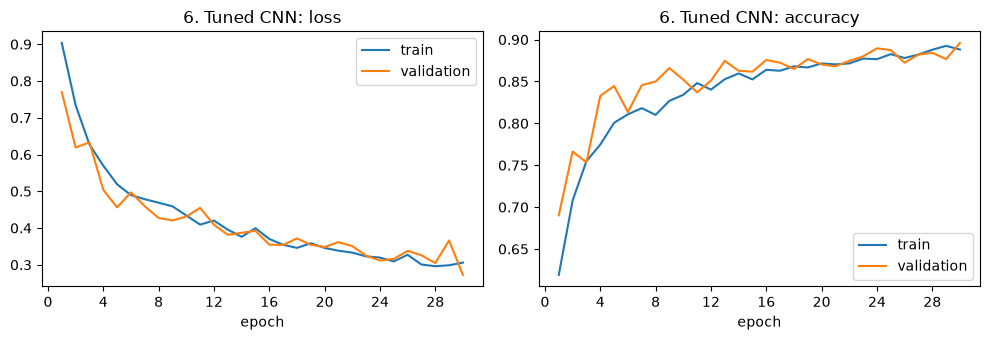

,validation accuracy
1. MLP baseline,0.7363
2. Simple CNN,0.8264
3. Deeper CNN + BatchNorm,0.9143
4. + augmentation + dropout,0.8907
5. Activation: Leaky ReLU,0.8917
5. Activation: ELU,0.8714
6. Tuned CNN,0.8960


In [65]:
tuned_cnn = train_model(build_best_cnn(), "6. Tuned CNN", loader=best_loader, learning_rate=best_learning_rate,
                        optimizer=best_optimizer, weight_decay=best["weight_decay"])
torch.save(tuned_cnn.state_dict(), f"{MODEL_DIR}/tuned_cnn.pt")
pd.Series(results, name="validation accuracy").round(4).to_frame()

**Observations**
- The tuned CNN reaches **89.6%** validation accuracy, 2.1 points more than the same settings in the 15-epoch search (87.5%). Its best epoch is again the last one (30), so it was still learning.
- **What mattered most** in the search was the learning rate: the chosen value (0.00091) is about 8 times larger than the worst runs used, so the model learns enough in the available epochs.
- **Compared with Section 3:** the tuned CNN beats the model it was tuned from (model 4, augmentation + dropout, 89.1%), but it is still below the deeper CNN without augmentation (91.4%). Within 30 epochs, a model without augmentation learns the training images faster. The tuned model has almost no gap between training and validation accuracy (88.8% and 89.6% at the end), so it has more room to improve with longer training.
- On the test set (Section 7), the tuned CNN reaches 91.3%.

---
# 5. Transfer learning with ResNet50

**ResNet50** (He et al., 2016) is a 50-layer CNN pretrained on ImageNet (1.2 million photos, 1,000 classes). Its **residual connections** add each block's input to its output, which lets the gradient flow through very deep networks. Its early layers detect general patterns (edges, textures, shapes) that are also useful for MRI scans, so we reuse them instead of learning everything from our 4,345 training images. Training has two stages:
1. **Feature extraction:** all pretrained layers are frozen and only a new final layer is trained.
2. **Fine-tuning:** the last block (`layer4`) is unfrozen and trained with a 10 times smaller learning rate, so the pretrained features are adjusted, not destroyed.

## 5.1 Loading and adapting the model
ResNet50 expects 3-channel colour images normalized with ImageNet's mean and standard deviation, and ends with a 1,000-class layer (`fc`). A small module in front of the network repeats our grayscale channel 3 times and applies the ImageNet normalization, and `fc` is replaced by a new layer with 4 outputs.

In [66]:
from torchvision.models import resnet50, ResNet50_Weights

class GrayToImageNet(nn.Module):
    """Turn a grayscale image (1 channel, 0–1) into the 3-channel, ImageNet-normalized input ResNet50 expects."""
    def __init__(self):
        super().__init__()
        # ImageNet's mean and standard deviation per colour channel. A buffer is a fixed tensor (not trained)
        # that moves to the GPU together with the model
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, x):
        return (x.repeat(1, 3, 1, 1) - self.mean) / self.std

torch.manual_seed(SEED)
backbone = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)   # pretrained on ImageNet
print("Original final layer:", backbone.fc)
backbone.fc = nn.Linear(backbone.fc.in_features, len(CLASSES)) # new layer: 2048 features → 4 classes
resnet = nn.Sequential(GrayToImageNet(), backbone)

Original final layer: Linear(in_features=2048, out_features=1000, bias=True)


## 5.2 Stage 1: feature extraction (frozen layers)
All pretrained weights are frozen (`requires_grad = False`), so only the new `fc` layer learns, with learning rate 0.001. The frozen layers' batch-normalization statistics are also kept fixed (see the training loop in Section 3). Training is fast, because gradients are only computed for the last layer.

Training: 7. ResNet50 (frozen) (23,516,228 parameters, 8,196 trainable)
Epoch  1 | train: loss 0.7495, accuracy 0.7277 | validation: loss 0.7062, accuracy 0.7835 | 34s
Epoch  2 | train: loss 0.4980, accuracy 0.8249 | validation: loss 0.6255, accuracy 0.7878 | 34s
Epoch  3 | train: loss 0.4245, accuracy 0.8451 | validation: loss 0.5480, accuracy 0.8221 | 34s
Epoch  4 | train: loss 0.3870, accuracy 0.8562 | validation: loss 0.4726, accuracy 0.8574 | 34s
Epoch  5 | train: loss 0.3569, accuracy 0.8725 | validation: loss 0.5226, accuracy 0.8296 | 34s
Epoch  6 | train: loss 0.3374, accuracy 0.8778 | validation: loss 0.4646, accuracy 0.8457 | 34s
Epoch  7 | train: loss 0.3167, accuracy 0.8856 | validation: loss 0.4758, accuracy 0.8424 | 34s
Epoch  8 | train: loss 0.3080, accuracy 0.8891 | validation: loss 0.4631, accuracy 0.8446 | 34s
Epoch  9 | train: loss 0.2904, accuracy 0.8969 | validation: loss 0.4246, accuracy 0.8542 | 34s
Epoch 10 | train: loss 0.2826, accuracy 0.8987 | validation: los

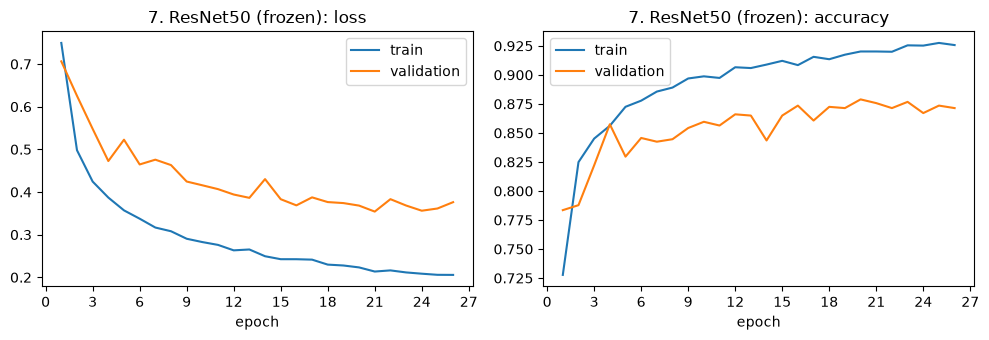

In [67]:
for parameter in backbone.parameters():
    parameter.requires_grad = False
for parameter in backbone.fc.parameters():
    parameter.requires_grad = True

resnet = train_model(resnet, "7. ResNet50 (frozen)", learning_rate=0.001)

**Observations**
- Only **8,196 of 23.5 million** parameters are trained (the new `fc` layer: 2,048 × 4 weights + 4 biases).
- Validation accuracy reaches **87.6%** (epoch 21) before early stopping at epoch 26. That is 3.8 points below our own deeper CNN (91.4%): ImageNet features learned from photos help, but without any change they are not specific enough for MRI scans.
- Training accuracy (92%) is not far above validation accuracy, so with so few trainable weights there is little overfitting.
- An epoch still takes about 34 seconds, because every image has to go through all 50 layers. Only the backward pass is cheap.

## 5.3 Stage 2: fine-tuning the last block
Starting from the stage-1 weights, the last residual block (`layer4`) is unfrozen as well. The learning rate drops 10 times, to 0.0001: a large learning rate would overwrite the pretrained features with noisy updates from our small dataset. The earlier blocks stay frozen, because they detect general patterns that need no change.

Training: 8. ResNet50 (fine-tuned) (23,516,228 parameters, 14,972,932 trainable)
Epoch  1 | train: loss 0.2402, accuracy 0.9082 | validation: loss 0.1976, accuracy 0.9335 | 86s
Epoch  2 | train: loss 0.1063, accuracy 0.9602 | validation: loss 0.1563, accuracy 0.9443 | 87s
Epoch  3 | train: loss 0.0690, accuracy 0.9756 | validation: loss 0.1800, accuracy 0.9421 | 72s
Epoch  4 | train: loss 0.0470, accuracy 0.9825 | validation: loss 0.1515, accuracy 0.9539 | 72s
Epoch  5 | train: loss 0.0367, accuracy 0.9857 | validation: loss 0.1399, accuracy 0.9550 | 72s
Epoch  6 | train: loss 0.0324, accuracy 0.9894 | validation: loss 0.1249, accuracy 0.9528 | 72s
Epoch  7 | train: loss 0.0256, accuracy 0.9910 | validation: loss 0.1531, accuracy 0.9593 | 73s
Epoch  8 | train: loss 0.0194, accuracy 0.9942 | validation: loss 0.1497, accuracy 0.9571 | 73s
Epoch  9 | train: loss 0.0242, accuracy 0.9922 | validation: loss 0.1514, accuracy 0.9582 | 72s
Epoch 10 | train: loss 0.0191, accuracy 0.9945 | valida

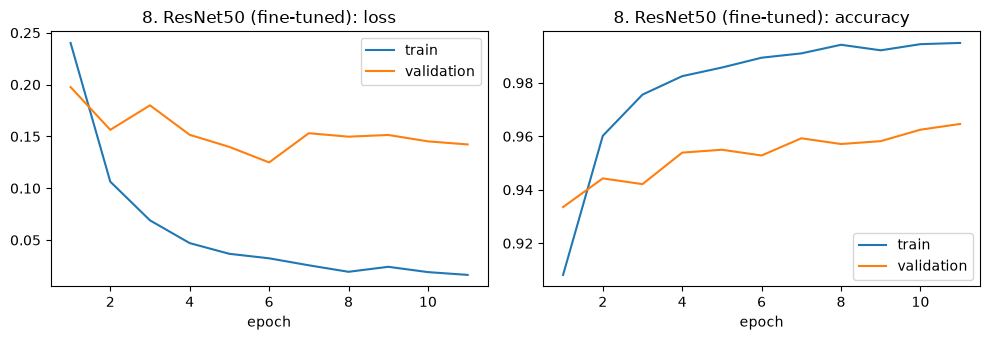

In [68]:
for parameter in backbone.layer4.parameters():
    parameter.requires_grad = True

resnet = train_model(resnet, "8. ResNet50 (fine-tuned)", learning_rate=0.0001)
torch.save(resnet.state_dict(), f"{MODEL_DIR}/resnet50.pt")

**Both stages together.** The validation accuracy of stage 1 followed by stage 2, with a line where fine-tuning starts.

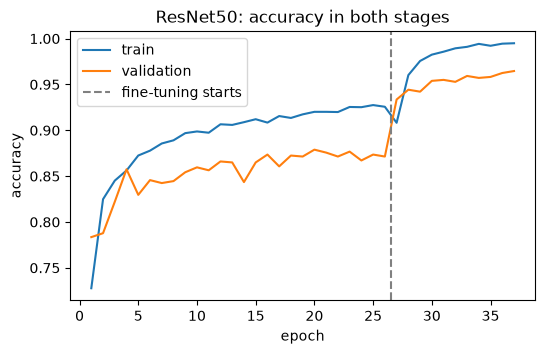

,validation accuracy
1. MLP baseline,0.7363
2. Simple CNN,0.8264
3. Deeper CNN + BatchNorm,0.9143
4. + augmentation + dropout,0.8907
5. Activation: Leaky ReLU,0.8917
5. Activation: ELU,0.8714
6. Tuned CNN,0.8960
7. ResNet50 (frozen),0.8757
8. ResNet50 (fine-tuned),0.9528


In [69]:
stage1 = histories["7. ResNet50 (frozen)"]
stage2 = histories["8. ResNet50 (fine-tuned)"]
train_accuracy = stage1["train_accuracy"] + stage2["train_accuracy"]   # stage 2 continues where stage 1 stopped
val_accuracy = stage1["val_accuracy"] + stage2["val_accuracy"]
epochs = range(1, len(val_accuracy) + 1)

plt.figure(figsize=(6, 3.5))
plt.plot(epochs, train_accuracy, label="train")
plt.plot(epochs, val_accuracy, label="validation")
plt.axvline(len(stage1["val_accuracy"]) + 0.5, color="gray", linestyle="--", label="fine-tuning starts")
plt.title("ResNet50: accuracy in both stages")
plt.xlabel("epoch")
plt.ylabel("accuracy")
plt.legend()
plt.show()

pd.Series(results, name="validation accuracy").round(4).to_frame()

**Observations**
- **Trainable parameters:** 8,196 in stage 1, and 14,972,932 in stage 2 (64% of the network, `layer4` + `fc`).
- **The jump when fine-tuning starts:** after one epoch of fine-tuning, validation accuracy goes from 87.6% to 93.4%. Adjusting the last block to MRI images is what makes the pretrained network really useful.
- The best weights are from epoch 6 (lowest validation loss): **95.3%** validation accuracy. Training accuracy goes up to 99.5%, so the model does overfit somewhat, but the validation loss stays low.
- **Compared with the tuned CNN:**
  - **Accuracy:** 5.7 points more on validation (95.3% vs 89.6%) and 5.2 points more on test (96.5% vs 91.3%).
  - **Size:** it trains 37 times more parameters (15.0 million vs 0.4 million).
  - **Speed:** each epoch is slower (72 s vs 30 s), but it needs fewer epochs. Both stages together took about 28 minutes, against about 15 minutes for the tuned CNN.
- With only 4,345 training images, starting from features learned on 1.2 million ImageNet images clearly works better than learning everything from scratch.

---
# 6. Integration of course topics

This table shows where each concept from the course is used in this notebook. Most of them were introduced step by step in Sections 2 to 5, and each one was chosen to solve a concrete problem of this dataset.

| Course topic | Section | What we did |
|---|---|---|
| Data preparation | 2 | Integrity check, outliers, exact and near-duplicate removal, stratified and grouped split, cropping, resizing, pixel scaling |
| Fully connected networks | 3.1 | MLP baseline on the raw pixels |
| CNN building blocks | 3.2, 3.3 | Convolution, max pooling, Flatten vs global average pooling |
| Activation functions | 3.1–3.5 | ReLU in all models; Leaky ReLU and ELU compared in 3.5; softmax inside the cross-entropy loss |
| Loss function | 3 | Cross-entropy with class weights for the imbalance left after duplicate removal |
| Backpropagation and the training loop | 3 | Forward pass, loss, backward pass and weight update for every batch |
| Batch normalization | 3.3 | After every convolution in the deeper CNN; kept frozen in 5.2 |
| Regularization | 2.5, 3.4, 4.1 | Data augmentation, dropout, L2 weight decay, early stopping |
| Optimization algorithms | 3, 4.3 | Adam; Adam vs SGD with momentum |
| Hyperparameter tuning | 4.1–4.4 | Random search over learning rate, dropout, network size and weight decay; batch sizes 16, 32 and 64; epochs set by early stopping |
| Advanced architectures | 5 | ResNet50 and its residual connections |
| Transfer learning | 5.2, 5.3 | Frozen feature extraction, then fine-tuning of `layer4` with a 10 times smaller learning rate |
| Evaluation metrics | 7 | Accuracy, precision, recall, F1, confusion matrix |

---
# 7. Evaluation and interpretation

The **test set** is used here for the first and only time. Three models are scored: the MLP baseline (3.1), the tuned CNN (4.4) and the fine-tuned ResNet50 (5.3). Nothing is changed after seeing these numbers, so they are an unbiased estimate of how the models do on new images. The best model is chosen by its **validation** accuracy, not its test accuracy.

## 7.1 Test accuracy
A helper function collects each model's predictions on the test set.

In [70]:
def predict(model, loader):
    """Predicted class of every image, in the loader's order."""
    model.eval()
    predictions = []
    with torch.no_grad():
        for images, _ in loader:
            predictions.append(model(images.to(device)).argmax(dim=1).cpu())
    return torch.cat(predictions).numpy()

final_models = {"1. MLP baseline": mlp, "6. Tuned CNN": tuned_cnn, "8. ResNet50 (fine-tuned)": resnet}
test_predictions = {}
test_accuracy = {}
for name, model in final_models.items():
    test_predictions[name] = predict(model, test_loader)
    test_accuracy[name] = (test_predictions[name] == y_test).mean()
    print(f"{name:<26} test accuracy {test_accuracy[name]:.4f}")

# The best model is chosen by validation accuracy, so the test set plays no part in the choice
best_name = max(final_models, key=lambda name: results[name])
print("\nBest model (by validation accuracy):", best_name)

1. MLP baseline            test accuracy 0.7267
6. Tuned CNN               test accuracy 0.9132
8. ResNet50 (fine-tuned)   test accuracy 0.9646

Best model (by validation accuracy): 8. ResNet50 (fine-tuned)


## 7.2 Precision, recall and F1 per class
**Precision:** of the images predicted as a class, how many really belong to it. **Recall:** of the images of a class, how many the model finds. **F1** combines the two. The macro average weighs every class equally, which matters because the classes are not balanced.

In [71]:
from sklearn.metrics import classification_report, confusion_matrix

for name, predictions in test_predictions.items():
    print(f"=== {name} ===")
    print(classification_report(y_test, predictions, target_names=CLASSES, digits=3))

=== 1. MLP baseline ===
              precision    recall  f1-score   support

      glioma      0.649     0.827     0.727       266
  meningioma      0.677     0.542     0.602       251
     notumor      0.821     0.623     0.708       154
   pituitary      0.819     0.863     0.840       262

    accuracy                          0.727       933
   macro avg      0.741     0.714     0.719       933
weighted avg      0.732     0.727     0.722       933

=== 6. Tuned CNN ===
              precision    recall  f1-score   support

      glioma      0.962     0.857     0.907       266
  meningioma      0.858     0.865     0.861       251
     notumor      0.898     0.968     0.931       154
   pituitary      0.931     0.985     0.957       262

    accuracy                          0.913       933
   macro avg      0.912     0.918     0.914       933
weighted avg      0.915     0.913     0.913       933

=== 8. ResNet50 (fine-tuned) ===
              precision    recall  f1-score   suppor

## 7.3 Confusion matrix
Rows are the true classes and columns the predicted classes: the diagonal holds the correct predictions, and every other cell shows which classes get mixed up.

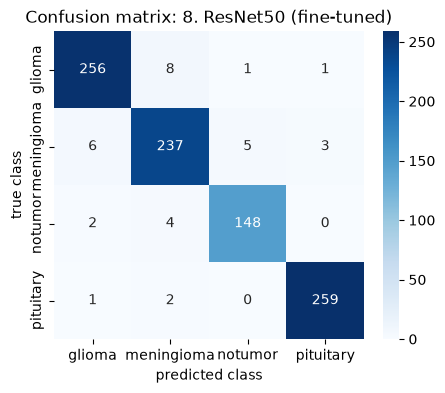

In [72]:
matrix = confusion_matrix(y_test, test_predictions[best_name])
plt.figure(figsize=(5, 4))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("predicted class")
plt.ylabel("true class")
plt.title(f"Confusion matrix: {best_name}")
plt.show()

## 7.4 Misclassified examples
Some test images the best model got wrong, with their true and predicted class.

33 of 933 test images are misclassified


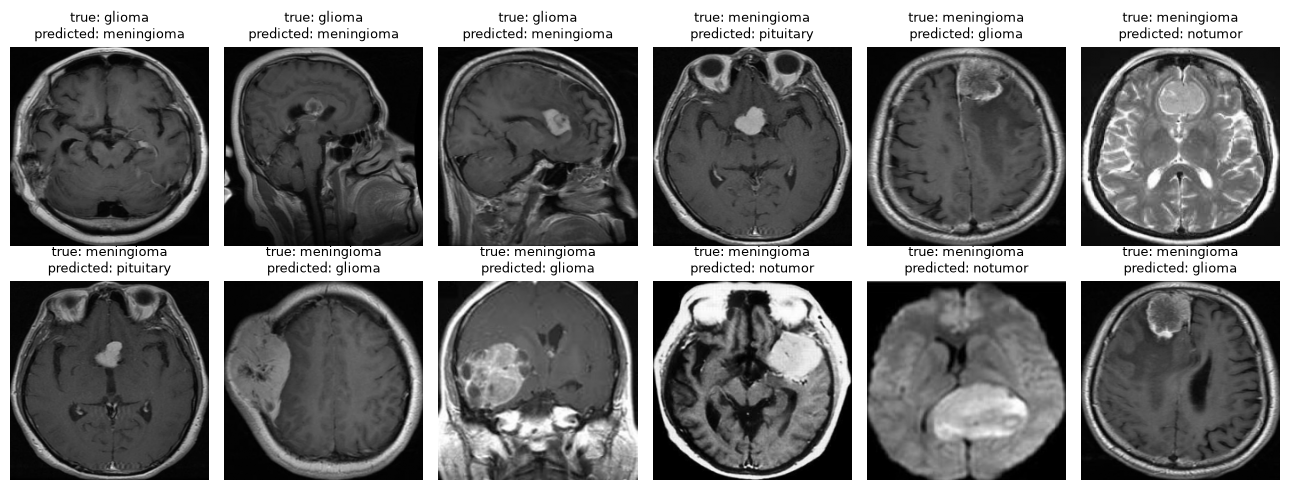

In [73]:
wrong = np.nonzero(test_predictions[best_name] != y_test)[0]
print(f"{len(wrong)} of {len(y_test)} test images are misclassified")

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, k in zip(axes.flat, wrong[:12]):
    ax.imshow(X_test[k, 0], cmap="gray")
    ax.set_title(f"true: {CLASSES[y_test[k]]}\npredicted: {CLASSES[test_predictions[best_name][k]]}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7.5 Final comparison
Validation accuracy of every model, and test accuracy of the three final models.

In [74]:
final_table = pd.DataFrame({"validation accuracy": pd.Series(results)})
final_table["test accuracy"] = pd.Series(test_accuracy)   # only the three final models have a test score
final_table.round(4)

,validation accuracy,test accuracy
1. MLP baseline,0.7363,0.7267
2. Simple CNN,0.8264,NaN
3. Deeper CNN + BatchNorm,0.9143,NaN
4. + augmentation + dropout,0.8907,NaN
5. Activation: Leaky ReLU,0.8917,NaN
5. Activation: ELU,0.8714,NaN
6. Tuned CNN,0.8960,0.9132
7. ResNet50 (frozen),0.8757,NaN
8. ResNet50 (fine-tuned),0.9528,0.9646


## 7.6 Interpretation
- **Validation vs test:** the test accuracy is close to the validation accuracy for all three models: 73.6% vs 72.7% (MLP), 89.6% vs 91.3% (tuned CNN), and 95.3% vs 96.5% (ResNet50). With 933 test images, 1 point is about 9 images, so these gaps are normal noise. Because similar images were kept in the same set (Section 2.3), the test accuracy is not inflated by near-copies of training images.
- **Which classes are confused:** glioma and meningioma are the hardest pair, as in other studies on this dataset. 14 of ResNet50's 33 errors are between them (8 gliomas predicted as meningioma, 6 meningiomas predicted as glioma). The tuned CNN has the same weakness, but worse: 30 gliomas are predicted as meningioma.
- **Recall of the tumor classes (ResNet50):** glioma 96.2%, meningioma 94.4% and pituitary 98.9%. Only **6 of the 779 tumor images** are predicted as "notumor" (1 glioma, 5 meningioma). These are the most dangerous errors. The tuned CNN made 17 of them.
- **Why recall matters most:** a missed tumor (false negative) delays treatment, while a false alarm only leads to another check by a radiologist. Recall on glioma, meningioma and pituitary is therefore more important than overall accuracy.
- **Source bias:** the "notumor" images come from a different source and are smaller and brighter (Section 2.1). If the model only used these differences, "notumor" would be recognized almost perfectly. In fact its recall (96.1%) is similar to the tumor classes, and 6 of its images are mistaken for tumors, so there is no sign that the model relies only on the source. We can't fully rule it out, though, because every "notumor" image comes from the same source.

## 7.7 Challenges and solutions

| Challenge | Solution |
|---|---|
| **Data leakage:** 23.1% of the original test images had an exact copy in the training folder, and many more had a near-copy or a neighbouring slice of the same patient | Exact duplicates removed with perceptual hashing (2.2), and near-duplicates grouped and kept in one set (2.2, 2.3) |
| **Class imbalance** after duplicate removal (1,023 to 1,774 images per class) | Stratified split, class weights in the loss, macro-averaged metrics |
| **Source bias:** "notumor" images come from another source and look different | Cropping and resizing remove the border and size differences; the bias is discussed in 7.6 |
| **Overfitting** on about 4,300 training images | Data augmentation, dropout, L2 weight decay, early stopping, transfer learning |
| **Unstable validation accuracy** of the batch-norm models in the first run (jumps from about 80% to 20% between epochs) | Batch-norm statistics recomputed over the whole training set after each epoch (training loop, Section 3) |
| **No patient IDs** in the dataset | Hash-based groups as an approximation; the remaining risk is stated in 2.2 |
| **Limited compute** (a laptop GPU, about 3 hours for the full notebook) | Shared training loop, short search runs (15 epochs), saved weights of the key models |

---
# 8. Final results and conclusions

| Model | Validation accuracy | Test accuracy |
|---|---|---|
| MLP baseline | 73.6% | 72.7% |
| Tuned CNN (trained from scratch) | 89.6% | 91.3% |
| **ResNet50 (fine-tuned)** | **95.3%** | **96.5%** |

**What helped most**
1. **Cleaning the data first.** 23% of the original test images had an exact copy in the training set, and many more had a near-copy. Without removing and grouping them, all test accuracies would look better than they really are.
2. **Convolutions and a good CNN structure.** Going from the MLP to the deeper CNN with batch normalization and global average pooling added about 18 points, while using fewer parameters.
3. **Transfer learning.** Fine-tuning a pretrained ResNet50 beat our best CNN trained from scratch by 5 points on the test set. Freezing everything was not enough (87.6%): the last block had to be fine-tuned.
4. **Checking strange learning curves.** The jumping validation accuracy in our first run came from batch-norm statistics, not from the models themselves. After fixing it, the CNN results went up by 6 to 10 points.

**Limitations**
- The dataset has **no patient IDs**. Our hash-based groups only catch images that look almost the same, so some slices of the same patient may still be split between training and test.
- Every model was trained once with **one random seed**, so differences under 1–2 points are not reliable.
- Training was cut at **30 epochs** (15 in the search), and several CNNs were still improving. Longer training would probably raise their scores.
- The "notumor" images come from a **different source**, which may make that class easier to recognize for the wrong reasons.
- The data comes from public datasets, not a hospital. This model is **not a medical tool** and must not be used for diagnosis.

**Next steps:** train longer and with several seeds, fine-tune more ResNet50 blocks, and test the model on an independent dataset that has patient IDs.

---
# 9. References

**Dataset**
- Nickparvar, M. (2021). *Brain Tumor MRI Dataset* (version 2). Kaggle. https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset
- Cheng, J. (2017). *Brain tumor dataset*. Figshare. https://doi.org/10.6084/m9.figshare.1512427, described in Cheng, J., et al. (2015). Enhanced performance of brain tumor classification via tumor region augmentation and partition. *PLoS ONE*, 10(10), e0140381.
- Bhuvaji, S., Kadam, A., Bhumkar, P., Dedge, S., & Kanchan, S. (2020). *Brain Tumor Classification (MRI)* (SARTAJ dataset). Kaggle. https://www.kaggle.com/datasets/sartajbhuvaji/brain-tumor-classification-mri
- Hamada, A. (2020). *Br35H: Brain Tumor Detection 2020*. Kaggle. https://www.kaggle.com/datasets/ahmedhamada0/brain-tumor-detection

**Methods**
- He, K., Zhang, X., Ren, S., & Sun, J. (2016). Deep residual learning for image recognition. *CVPR*, 770–778.
- Deng, J., et al. (2009). ImageNet: A large-scale hierarchical image database. *CVPR*, 248–255.
- Ioffe, S., & Szegedy, C. (2015). Batch normalization: Accelerating deep network training by reducing internal covariate shift. *ICML*, 448–456.
- Wu, Y., & Johnson, J. (2021). Rethinking "batch" in BatchNorm. *arXiv:2105.07576*.
- Srivastava, N., Hinton, G., Krizhevsky, A., Sutskever, I., & Salakhutdinov, R. (2014). Dropout: A simple way to prevent neural networks from overfitting. *JMLR*, 15, 1929–1958.
- Kingma, D. P., & Ba, J. (2015). Adam: A method for stochastic optimization. *ICLR*.
- Bergstra, J., & Bengio, Y. (2012). Random search for hyper-parameter optimization. *JMLR*, 13, 281–305.
- Maas, A. L., Hannun, A. Y., & Ng, A. Y. (2013). Rectifier nonlinearities improve neural network acoustic models. *ICML Workshop on Deep Learning for Audio, Speech and Language Processing*.
- Clevert, D.-A., Unterthiner, T., & Hochreiter, S. (2016). Fast and accurate deep network learning by exponential linear units (ELUs). *ICLR*.

**Software**
- Paszke, A., et al. (2019). PyTorch: An imperative style, high-performance deep learning library. *NeurIPS*, 32. torchvision: https://pytorch.org/vision
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.
- Buchner, J. *ImageHash* (perceptual image hashing). https://github.com/JohannesBuchner/imagehash
- Bradski, G. (2000). The OpenCV library. *Dr. Dobb's Journal of Software Tools*.